In [1]:
from google.colab import files

uploaded = files.upload()

Saving starbucks_customer_ordering_patterns.csv to starbucks_customer_ordering_patterns.csv


In [2]:
!pip install kaggle

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Tools for preparing the data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Tools for reducing features
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif

# Ml models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Tools to measure model performance
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

In [5]:
import warnings
warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

In [6]:
df = pd.read_csv('starbucks_customer_ordering_patterns.csv')

In [7]:
df.head()

,customer_id,order_id,order_date,order_time,day_of_week,order_channel,store_id,store_location_type,region,customer_age_group,customer_gender,is_rewards_member,cart_size,num_customizations,total_spend,fulfillment_time_min,drink_category,has_food_item,order_ahead,customer_satisfaction
0,CUST_12974,ORD_00000001,2024-03-25,08:47,Mon,Drive-Thru,STR_340,Suburban,Southwest,18-24,Male,False,5,0,14.48,8.2,Refresher,False,False,4
1,CUST_08235,ORD_00000002,2025-07-18,08:02,Fri,Mobile App,STR_425,Urban,Northeast,35-44,Female,True,1,3,9.52,5.4,Brewed Coffee,False,True,4
2,CUST_00393,ORD_00000003,2025-01-15,05:40,Wed,Kiosk,STR_103,Suburban,Midwest,25-34,Female,False,2,1,9.32,4.9,Brewed Coffee,False,False,5
3,CUST_06936,ORD_00000004,2024-07-30,15:10,Tue,Drive-Thru,STR_318,Suburban,Midwest,25-34,Female,True,2,1,9.55,3.5,Refresher,False,False,4
4,CUST_09800,ORD_00000005,2024-06-18,07:38,Tue,Drive-Thru,STR_338,Suburban,Northeast,35-44,Female,False,3,1,12.24,4.1,Frappuccino,False,False,3


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   customer_id            100000 non-null  object 
 1   order_id               100000 non-null  object 
 2   order_date             100000 non-null  object 
 3   order_time             100000 non-null  object 
 4   day_of_week            100000 non-null  object 
 5   order_channel          100000 non-null  object 
 6   store_id               100000 non-null  object 
 7   store_location_type    100000 non-null  object 
 8   region                 100000 non-null  object 
 9   customer_age_group     100000 non-null  object 
 10  customer_gender        100000 non-null  object 
 11  is_rewards_member      100000 non-null  bool   
 12  cart_size              100000 non-null  int64  
 13  num_customizations     100000 non-null  int64  
 14  total_spend            100000 non-nul

In [9]:
df.describe()

,cart_size,num_customizations,total_spend,fulfillment_time_min,customer_satisfaction
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000
mean,3.741510,1.81077,14.866771,4.546080,3.687530
std,1.697817,1.46280,5.506800,1.550269,1.184123
min,1.000000,0.00000,3.510000,1.000000,1.000000
25%,3.000000,1.00000,10.837500,3.400000,3.000000
50%,4.000000,2.00000,14.170000,4.400000,4.000000
75%,5.000000,3.00000,18.180000,5.500000,5.000000
max,10.000000,8.00000,40.310000,11.200000,5.000000


In [10]:
df.columns

Index(['customer_id', 'order_id', 'order_date', 'order_time', 'day_of_week',
       'order_channel', 'store_id', 'store_location_type', 'region',
       'customer_age_group', 'customer_gender', 'is_rewards_member',
       'cart_size', 'num_customizations', 'total_spend',
       'fulfillment_time_min', 'drink_category', 'has_food_item',
       'order_ahead', 'customer_satisfaction'],
      dtype='object')

In [11]:
df.dtypes

,0
customer_id,object
order_id,object
order_date,object
order_time,object
day_of_week,object
order_channel,object
store_id,object
store_location_type,object
region,object
customer_age_group,object


In [12]:
df.isnull().sum()

,0
customer_id,0
order_id,0
order_date,0
order_time,0
day_of_week,0
order_channel,0
store_id,0
store_location_type,0
region,0
customer_age_group,0


In [13]:
df.size

2000000

In [14]:
(df.isnull().sum().sum() / df.size) * 100

np.float64(0.0)

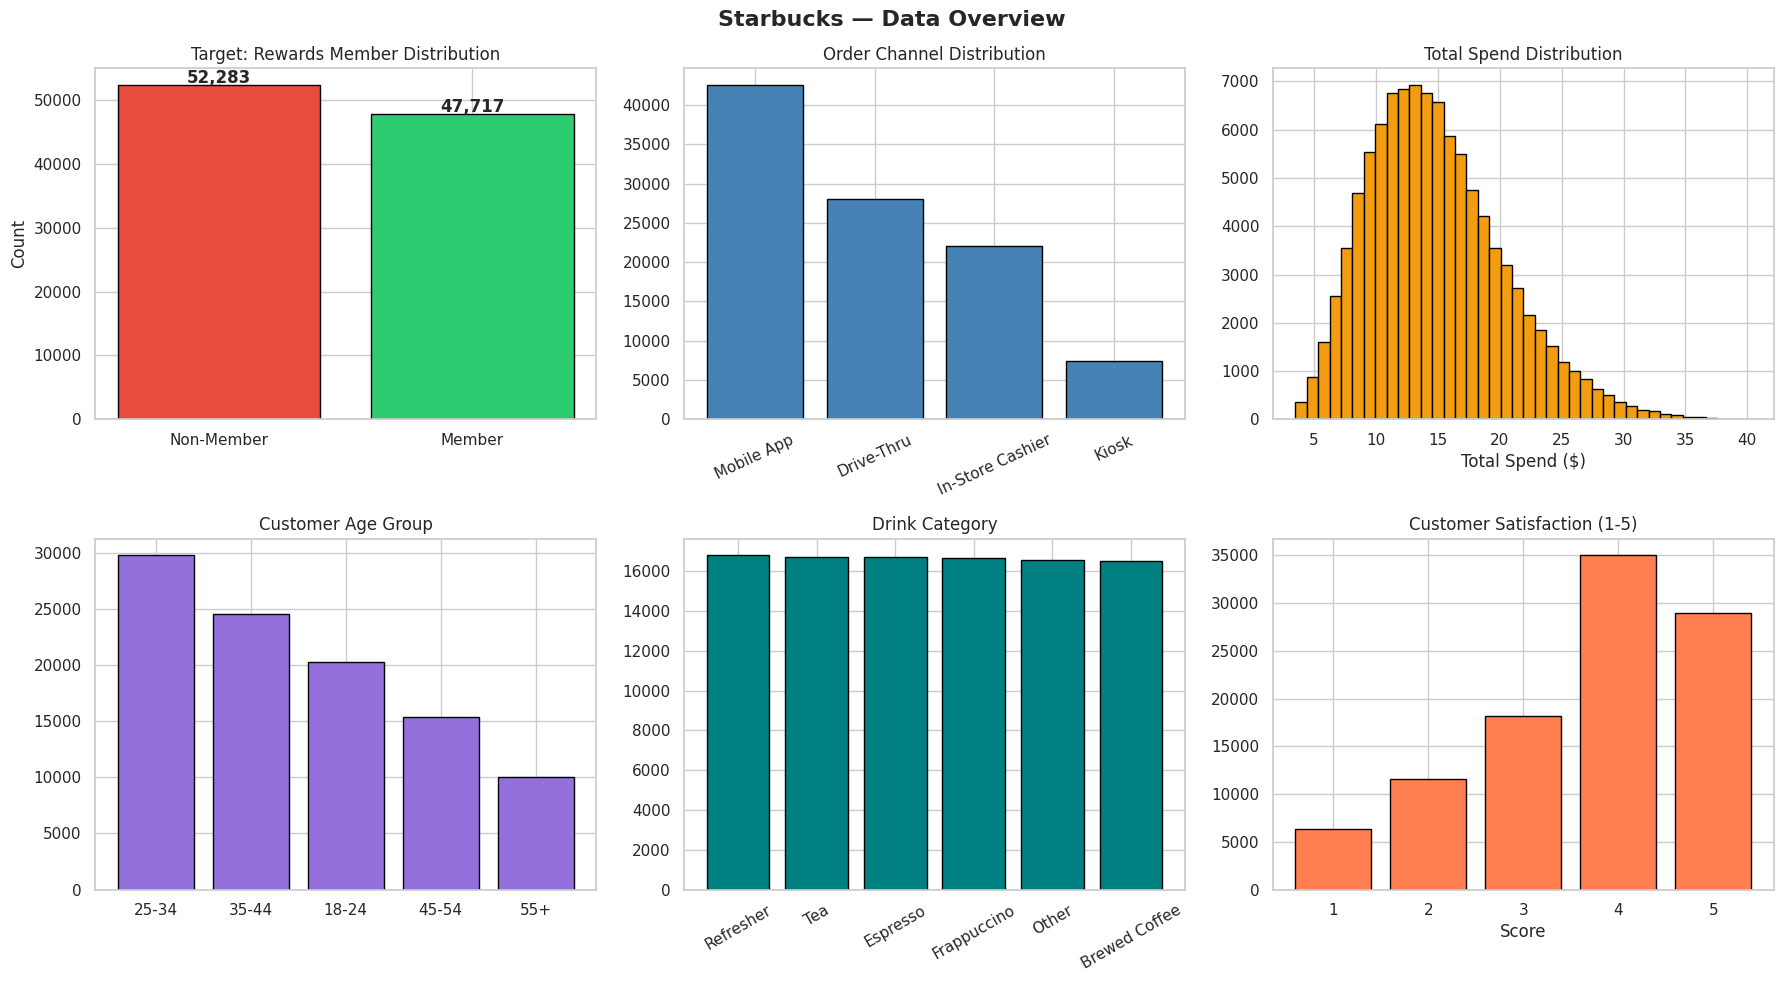

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Starbucks — Data Overview', fontsize=16, fontweight='bold')
vals = df['is_rewards_member'].value_counts()
axes[0, 0].bar(['Non-Member', 'Member'], vals.values,
               color=['#e74c3c', '#2ecc71'], edgecolor='black')
axes[0, 0].set_title('Target: Rewards Member Distribution')
axes[0, 0].set_ylabel('Count')
for i, v in enumerate(vals.values):
    axes[0, 0].text(i, v + 300, f'{v:,}', ha='center', fontweight='bold')
oc = df['order_channel'].value_counts()
axes[0, 1].bar(oc.index, oc.values, color='steelblue', edgecolor='black')
axes[0, 1].set_title('Order Channel Distribution')
axes[0, 1].tick_params(axis='x', rotation=25)

#  Total spend
axes[0, 2].hist(df['total_spend'], bins=40, color='#f39c12', edgecolor='black')
axes[0, 2].set_title('Total Spend Distribution')
axes[0, 2].set_xlabel('Total Spend ($)')

# Age groups
ag = df['customer_age_group'].value_counts()
axes[1, 0].bar(ag.index, ag.values, color='mediumpurple', edgecolor='black')
axes[1, 0].set_title('Customer Age Group')

#  Drink categories
dc = df['drink_category'].value_counts()
axes[1, 1].bar(dc.index, dc.values, color='teal', edgecolor='black')
axes[1, 1].set_title('Drink Category')
axes[1, 1].tick_params(axis='x', rotation=30)

#  Customer satisfaction scores
sat = df['customer_satisfaction'].value_counts().sort_index()
axes[1, 2].bar(sat.index, sat.values, color='coral', edgecolor='black')
axes[1, 2].set_title('Customer Satisfaction (1-5)')
axes[1, 2].set_xlabel('Score')

plt.tight_layout()
plt.savefig('eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()

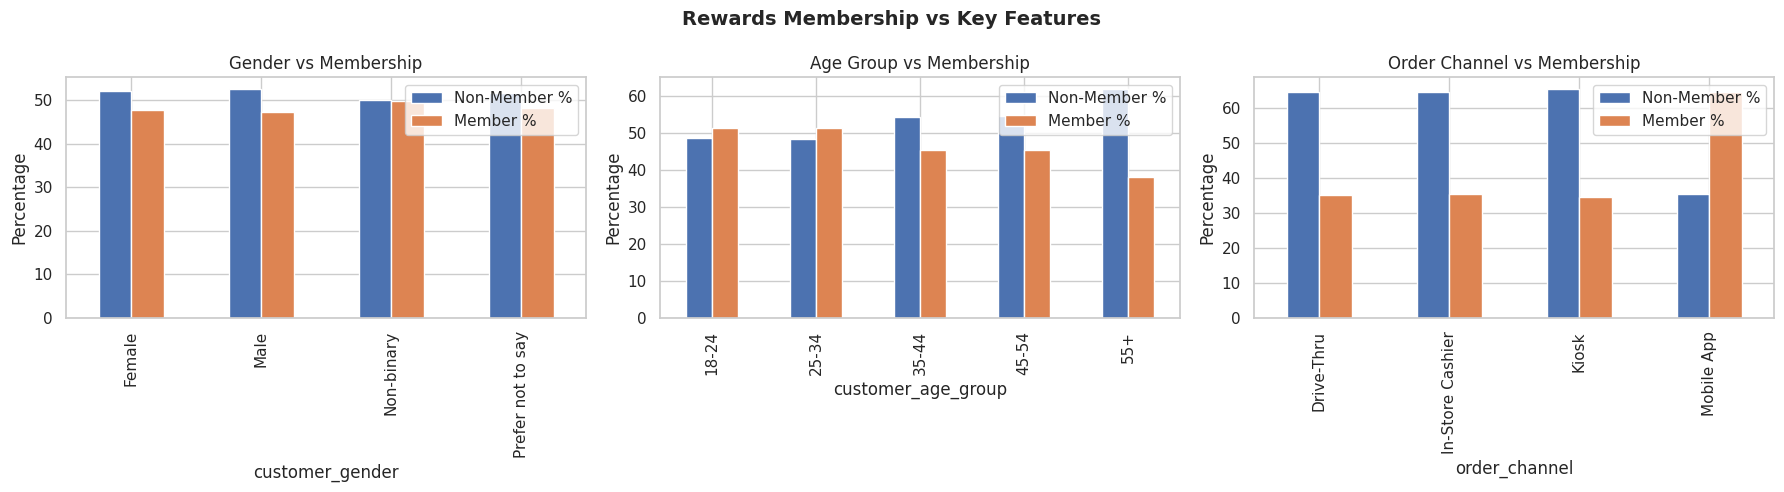

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Rewards Membership vs Key Features', fontsize=14, fontweight='bold')

# Gender vs membership
ct1 = pd.crosstab(df['customer_gender'],
                  df['is_rewards_member'],
                  normalize='index') * 100
ct1.columns = ['Non-Member %', 'Member %']
ct1.plot(kind='bar', ax=axes[0])
axes[0].set_title('Gender vs Membership')
axes[0].set_ylabel('Percentage')

# Age group vs membership
ct2 = pd.crosstab(df['customer_age_group'],
                  df['is_rewards_member'],
                  normalize='index') * 100
ct2.columns = ['Non-Member %', 'Member %']
ct2.plot(kind='bar', ax=axes[1])
axes[1].set_title('Age Group vs Membership')
axes[1].set_ylabel('Percentage')

# Order channel vs membership
ct3 = pd.crosstab(df['order_channel'],
                  df['is_rewards_member'],
                  normalize='index') * 100
ct3.columns = ['Non-Member %', 'Member %']
ct3.plot(kind='bar', ax=axes[2])
axes[2].set_title('Order Channel vs Membership')
axes[2].set_ylabel('Percentage')

plt.tight_layout()
plt.savefig('eda_target.png', dpi=150)
plt.show()

In [18]:
df_model = df.copy()

In [19]:
df_model = df_model.drop(columns=['customer_id', 'order_id', 'order_date', 'store_id'])

In [20]:
df_model['hour'] = pd.to_datetime(df_model['order_time'], format='%H:%M').dt.hour
df_model = df_model.drop(columns=['order_time'])

In [21]:
for col in ['has_food_item', 'order_ahead']:
    df_model[col] = df_model[col].astype(int)

In [22]:
df_model['is_rewards_member'] = df_model['is_rewards_member'].astype(int)

In [23]:
cat_cols = [
    'day_of_week', 'order_channel', 'store_location_type',
    'region', 'customer_age_group', 'customer_gender', 'drink_category'
]
df_model = pd.get_dummies(df_model, columns=cat_cols, drop_first=True)

In [24]:
print(f"Final shape  : {df_model.shape}")
print(f"Features     : {df_model.shape[1] - 1}")
print("Target distribution:")
print(df_model['is_rewards_member'].value_counts())

Final shape  : (100000, 36)
Features     : 35
Target distribution:
is_rewards_member
0    52283
1    47717
Name: count, dtype: int64


In [25]:
df_model.head(3)

,is_rewards_member,cart_size,num_customizations,total_spend,fulfillment_time_min,has_food_item,order_ahead,customer_satisfaction,hour,day_of_week_Mon,...,customer_age_group_45-54,customer_age_group_55+,customer_gender_Male,customer_gender_Non-binary,customer_gender_Prefer not to say,drink_category_Espresso,drink_category_Frappuccino,drink_category_Other,drink_category_Refresher,drink_category_Tea
0,0,5,0,14.48,8.2,0,0,4,8,True,...,False,False,True,False,False,False,False,False,True,False
1,1,1,3,9.52,5.4,0,1,4,8,False,...,False,False,False,False,False,False,False,False,False,False
2,0,2,1,9.32,4.9,0,0,5,5,False,...,False,False,False,False,False,False,False,False,False,False


In [26]:
X = df_model.drop(columns=['is_rewards_member'])
y = df_model['is_rewards_member']

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [28]:
print(f"Training samples : {X_train.shape[0]:,}")
print(f"Testing samples  : {X_test.shape[0]:,}")
print(f"Number of features: {X_train.shape[1]}")

Training samples : 80,000
Testing samples  : 20,000
Number of features: 35


In [29]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [30]:
corr_df     = pd.DataFrame(X_train_scaled, columns=X.columns)
corr_matrix = corr_df.corr().abs()

In [31]:
top_features = corr_matrix.mean().nlargest(20).index

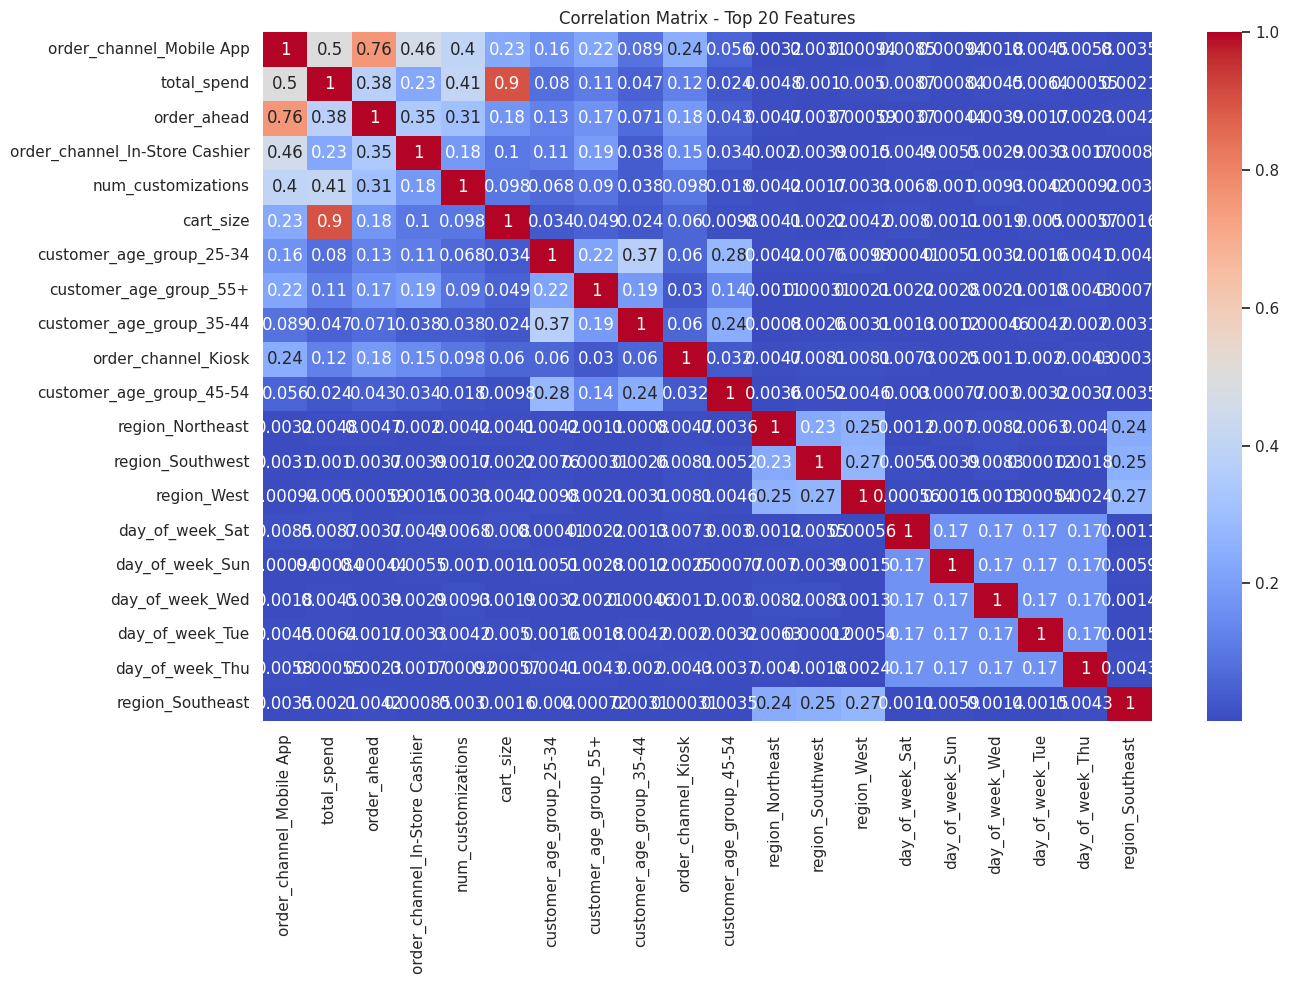

In [32]:
my_cmap = 'coolwarm'
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix.loc[top_features, top_features],
    annot=True,
    cmap=my_cmap
)

plt.title('Correlation Matrix - Top 20 Features')
plt.tight_layout()
plt.show()

In [33]:
upper  = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if any(upper[col] > 0.90)]

In [34]:
print("Removed features:", to_drop)

Removed features: ['total_spend']


In [35]:
X_train_corr = pd.DataFrame(X_train_scaled, columns=X.columns).drop(columns=to_drop).values
X_test_corr  = pd.DataFrame(X_test_scaled,  columns=X.columns).drop(columns=to_drop).values

print("Remaining features:", X_train_corr.shape[1])

Remaining features: 34


In [36]:
selector = SelectKBest(score_func=f_classif, k=15)

X_train_kbest = selector.fit_transform(X_train_scaled, y_train)
X_test_kbest  = selector.transform(X_test_scaled)

In [37]:
sel_mask   = selector.get_support()
sel_feats  = X.columns[sel_mask]
sel_scores = selector.scores_[sel_mask]

In [38]:
feat_df = pd.DataFrame({'Feature': sel_feats, 'F-Score': sel_scores})
feat_df = feat_df.sort_values('F-Score')

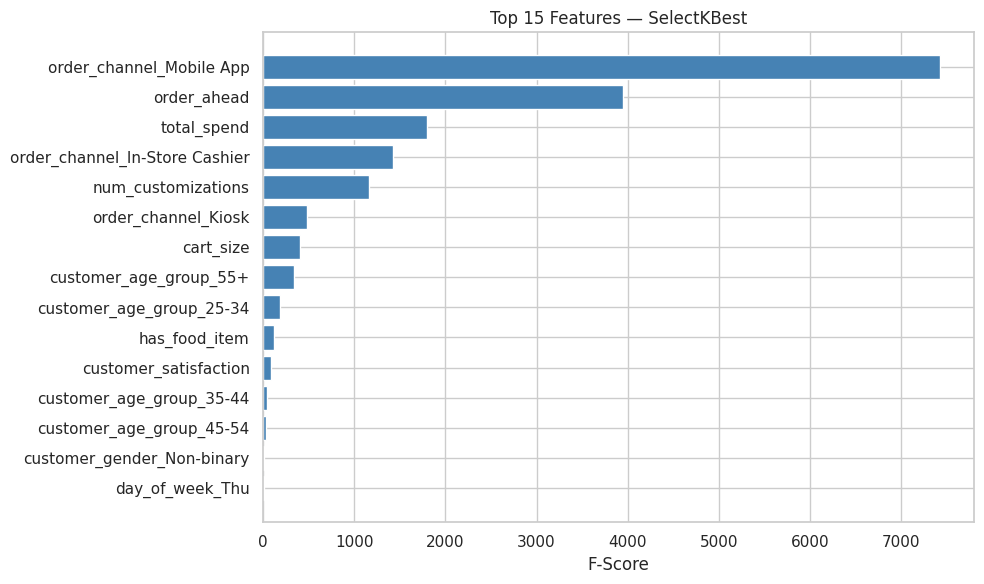

In [39]:
plt.figure(figsize=(10, 6))
plt.barh(feat_df['Feature'], feat_df['F-Score'], color='steelblue')
plt.xlabel('F-Score')
plt.title('Top 15 Features — SelectKBest')
plt.tight_layout()
plt.show()

In [40]:
print("Selected features:", list(sel_feats))

Selected features: ['cart_size', 'num_customizations', 'total_spend', 'has_food_item', 'order_ahead', 'customer_satisfaction', 'day_of_week_Thu', 'order_channel_In-Store Cashier', 'order_channel_Kiosk', 'order_channel_Mobile App', 'customer_age_group_25-34', 'customer_age_group_35-44', 'customer_age_group_45-54', 'customer_age_group_55+', 'customer_gender_Non-binary']


In [41]:
pca = PCA(n_components=0.95, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca  = pca.transform(X_test_scaled)

In [42]:
print("Original features :", X_train_scaled.shape[1])
print("PCA components    :", pca.n_components_)
print(f"Variance retained : {pca.explained_variance_ratio_.sum() * 100:.2f}%")

Original features : 35
PCA components    : 28
Variance retained : 96.00%


In [43]:
cumvar = np.cumsum(pca.explained_variance_ratio_) * 100

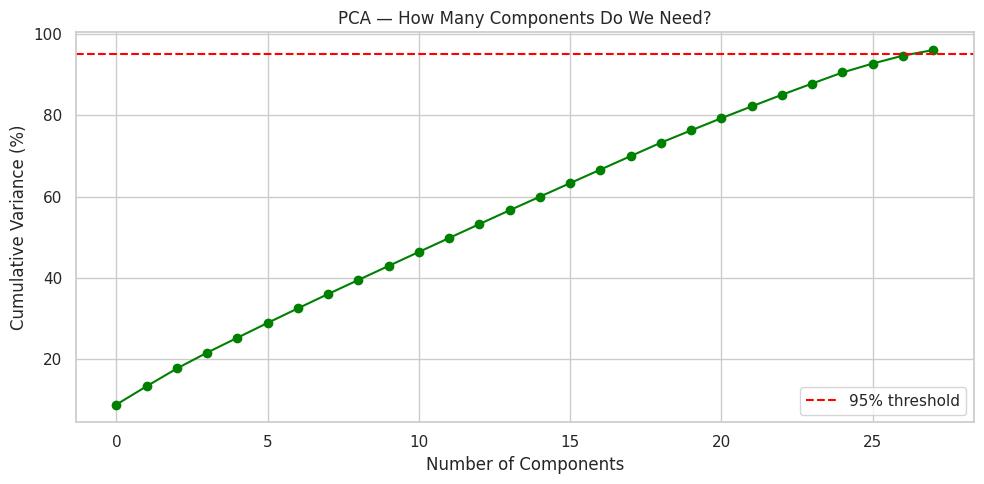

In [44]:
plt.figure(figsize=(10, 5))
plt.plot(cumvar, marker='o', color='green')
plt.axhline(95, color='red', linestyle='--', label='95% threshold')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Variance (%)')
plt.title('PCA — How Many Components Do We Need?')
plt.legend()
plt.tight_layout()
plt.show()

In [45]:
results = {}

def evaluate(name, model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)

    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]

    acc = accuracy_score(y_te, y_pred)
    auc = roc_auc_score(y_te, y_prob)

    results[name] = {
        'Accuracy': acc,
        'AUC': auc,
        'y_pred': y_pred,
        'y_prob': y_prob,
        'model': model
    }

    print(f"--- {name} ---")
    print(f"Accuracy : {acc:.4f}")
    print(f"AUC      : {auc:.4f}")
    print(classification_report(
        y_te, y_pred,
        target_names=['Non-Member', 'Member'],
        zero_division=0
    ))

In [46]:
datasets = {
    'Original': (X_train_scaled, X_test_scaled),
    'Corr':     (X_train_corr,   X_test_corr),
    'KBest':    (X_train_kbest,  X_test_kbest),
    'PCA':      (X_train_pca,    X_test_pca)
}

In [47]:
models = {
    'LR': LogisticRegression(max_iter=1000),
    'DT': DecisionTreeClassifier(max_depth=6),
    'RF': RandomForestClassifier(n_estimators=100)
}

In [69]:
for model_name, model in models.items():
    for data_name, (Xtr, Xte) in datasets.items():
        key = f"{model_name}-{data_name}"
        evaluate(key, model, Xtr, Xte, y_train, y_test)

print("\nAll models trained!")

--- LR-Original ---
Accuracy : 0.6468
AUC      : 0.6445
              precision    recall  f1-score   support

  Non-Member       0.65      0.71      0.68     10457
      Member       0.64      0.58      0.61      9543

    accuracy                           0.65     20000
   macro avg       0.65      0.64      0.64     20000
weighted avg       0.65      0.65      0.65     20000

--- LR-Corr ---
Accuracy : 0.6468
AUC      : 0.6445
              precision    recall  f1-score   support

  Non-Member       0.65      0.71      0.68     10457
      Member       0.64      0.58      0.61      9543

    accuracy                           0.65     20000
   macro avg       0.65      0.64      0.64     20000
weighted avg       0.65      0.65      0.65     20000

--- LR-KBest ---
Accuracy : 0.6468
AUC      : 0.6458
              precision    recall  f1-score   support

  Non-Member       0.65      0.71      0.68     10457
      Member       0.64      0.58      0.61      9543

    accuracy         

In [54]:
final_summary = pd.DataFrame({
    key: {
        'Accuracy (%)': round(val['Accuracy'] * 100, 2),
        'AUC': round(val['AUC'], 4)
    }
    for key, val in results.items()
}).T.sort_values('Accuracy (%)', ascending=False)

print("       FINAL LEADERBOARD")
print(final_summary.head(10).to_string())

best_name = final_summary.index[0]
best_acc  = final_summary.iloc[0]['Accuracy (%)']
best_auc  = final_summary.iloc[0]['AUC']

print()
print("      Best Model Result")
print(f"Model    : {best_name}")
print(f"Accuracy : {best_acc}%")
print(f"AUC      : {best_auc}")

       FINAL LEADERBOARD
             Accuracy (%)     AUC
LR-Original         64.68  0.6445
LR-Corr             64.68  0.6445
LR-KBest            64.68  0.6458
DT-KBest            64.64  0.6450
DT-Original         64.62  0.6440
DT-Corr             64.56  0.6462
LR-PCA              64.44  0.6420
DT-PCA              63.73  0.6388
RF-Original         63.51  0.6395
RF-Corr             63.18  0.6378

      Best Model Result
Model    : LR-Original
Accuracy : 64.68%
AUC      : 0.6445


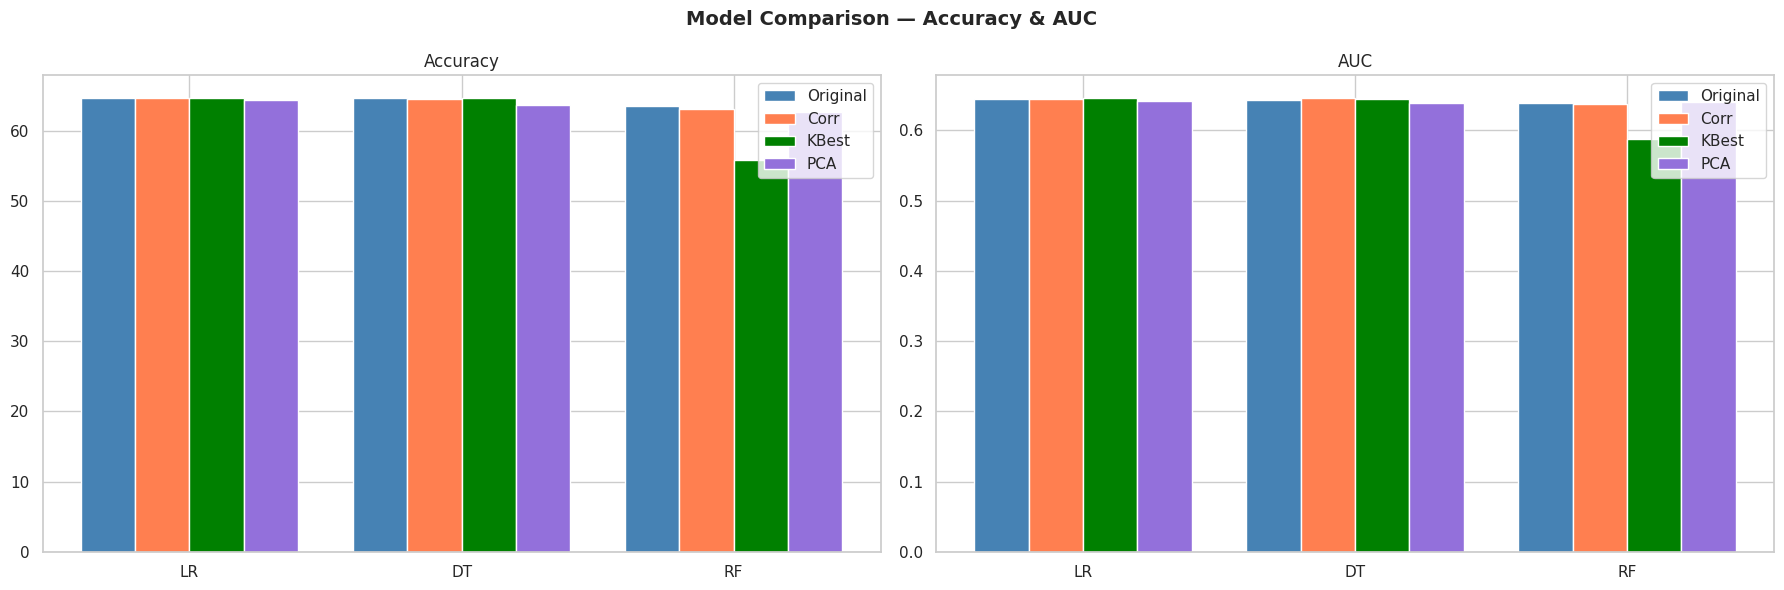

In [55]:
model_labels = ['LR', 'DT', 'RF']
ds_labels    = ['Original', 'Corr', 'KBest', 'PCA']

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Model Comparison — Accuracy & AUC', fontsize=14, fontweight='bold')

x     = np.arange(len(model_labels))
width = 0.2

colors = ['steelblue', 'coral', 'green', 'mediumpurple']

for i, metric in enumerate(['Accuracy', 'AUC']):
    ax = axes[i]
    for j, ds in enumerate(ds_labels):
        vals = []
        for m in model_labels:
            key = f"{m}-{ds}"
            if metric == 'Accuracy':
                vals.append(results[key]['Accuracy'] * 100)
            else:
                vals.append(results[key]['AUC'])
        ax.bar(x + j * width, vals, width, label=ds, color=colors[j])

    ax.set_title(metric)
    ax.set_xticks(x + width * 1.5)
    ax.set_xticklabels(model_labels)
    ax.legend()

plt.tight_layout()
plt.show()

In [56]:
best_models = {}
for prefix in ['LR', 'DT', 'RF']:
    candidates = [k for k in results if k.startswith(prefix)]
    best_key = max(candidates, key=lambda k: results[k]['AUC'])
    best_models[prefix] = best_key

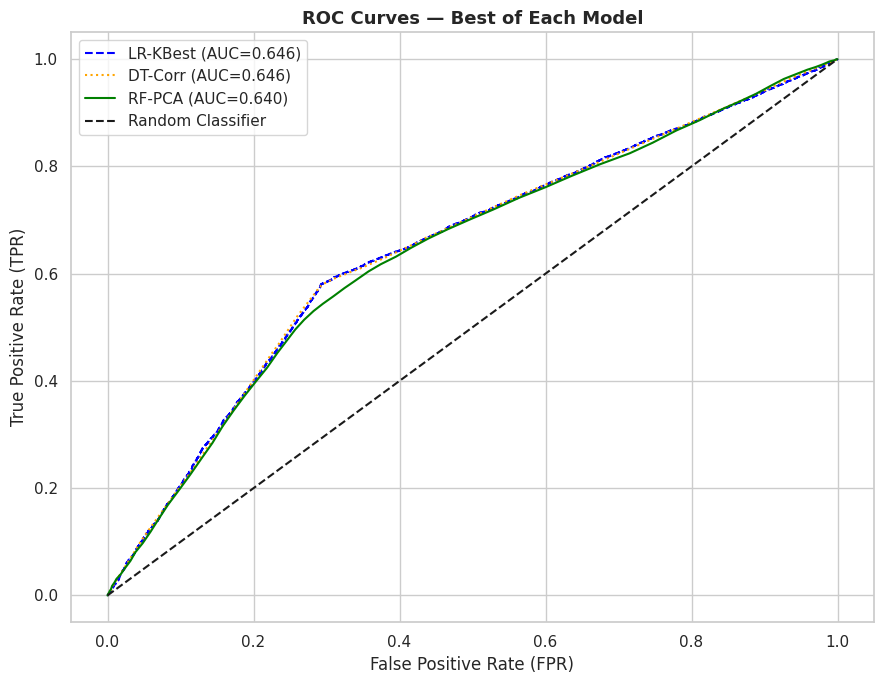

In [57]:
fig, ax = plt.subplots(figsize=(9, 7))

styles = {'LR': '--', 'DT': ':', 'RF': '-'}
colors = {'LR': 'blue', 'DT': 'orange', 'RF': 'green'}

for prefix, key in best_models.items():
    fpr, tpr, _ = roc_curve(y_test, results[key]['y_prob'])
    auc_val = results[key]['AUC']
    ax.plot(fpr, tpr,
            linestyle=styles[prefix],
            color=colors[prefix],
            label=f"{key} (AUC={auc_val:.3f})")

# Diagonal line (random model)
ax.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

ax.set_title('ROC Curves — Best of Each Model', fontsize=13, fontweight='bold')
ax.set_xlabel('False Positive Rate (FPR)')
ax.set_ylabel('True Positive Rate (TPR)')
ax.legend()
plt.tight_layout()
plt.show()


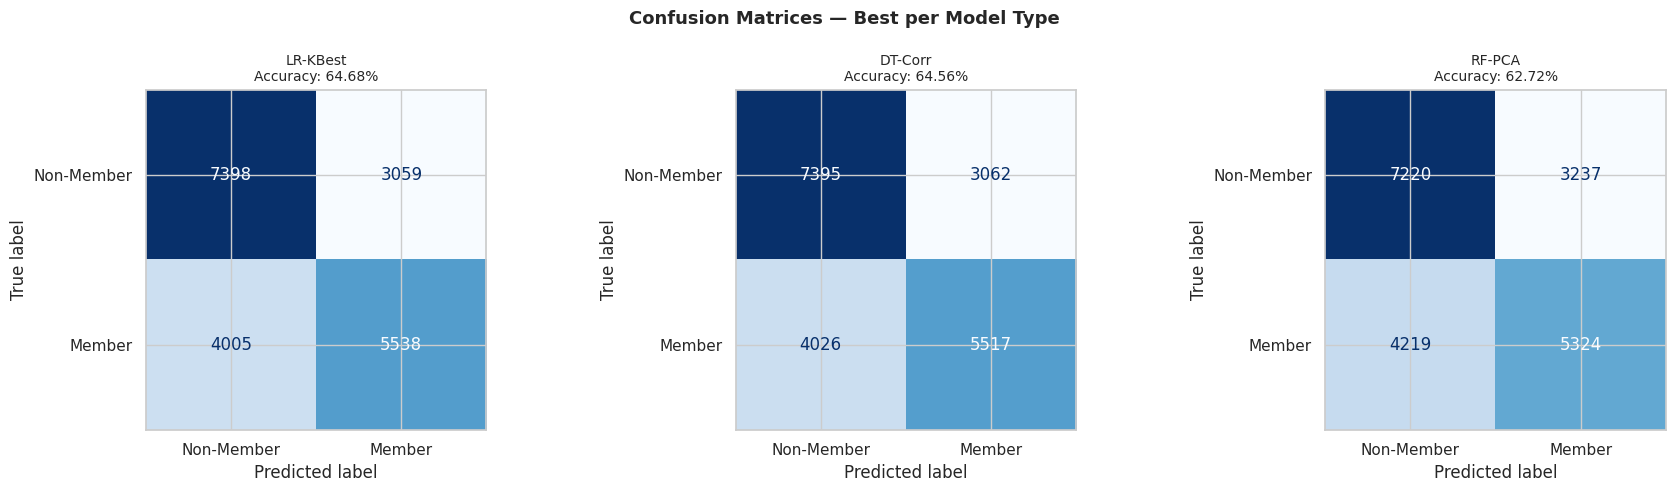

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Confusion Matrices — Best per Model Type', fontsize=13, fontweight='bold')

for ax, (prefix, key) in zip(axes, best_models.items()):
    cm   = confusion_matrix(y_test, results[key]['y_pred'])
    disp = ConfusionMatrixDisplay(cm, display_labels=['Non-Member', 'Member'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    acc  = results[key]['Accuracy'] * 100
    ax.set_title(f"{key}\nAccuracy: {acc:.2f}%", fontsize=10)

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

In [59]:
rf_best_key   = max([k for k in results if k.startswith('RF')],
                    key=lambda k: results[k]['Accuracy'])
rf_best_model = results[rf_best_key]['model']

#  which feature names to use based on the dataset
ds_used = rf_best_key.split('-')[1]
if ds_used == 'Original':
    feat_names = X.columns.tolist()
elif ds_used == 'Corr':
    remaining_cols = [c for c in X.columns if c not in to_drop]
    feat_names = remaining_cols
elif ds_used == 'KBest':
    feat_names = list(sel_feats)
else:
    feat_names = [f'PC{i+1}' for i in range(rf_best_model.n_features_in_)]

# Plot top 20 feature importances
try:
    importances = pd.Series(rf_best_model.feature_importances_, index=feat_names)
    top20 = importances.nlargest(20).sort_values()
    plt.figure(figsize=(10, 7))
    top20.plot(kind='barh', color='darkorange', edgecolor='black')
    plt.title(f'Top 20 Most Important Features — {rf_best_key}', fontweight='bold')
    plt.xlabel('Importance Score')
    plt.tight_layout()
    plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
    plt.show()

    print("Top 10 Features:")
    print(top20.tail(10).iloc[::-1].to_string())
except Exception as e:
    print(f"Note: {e}")

Note: Length of values (28) does not match length of index (35)


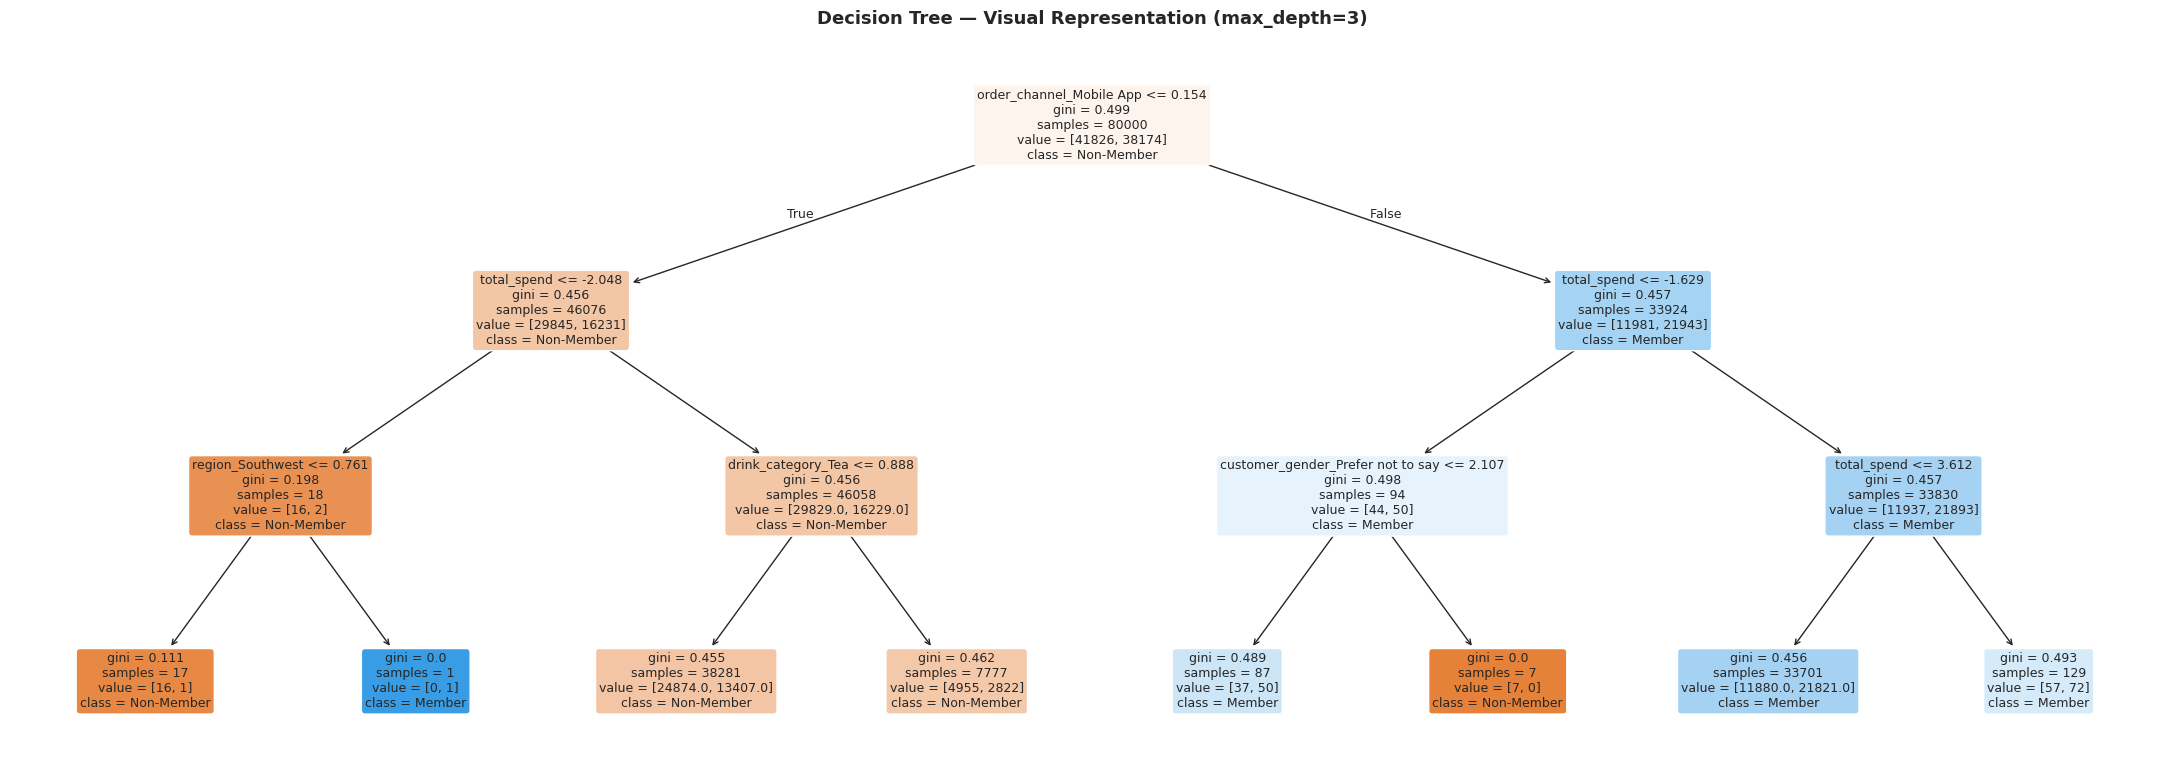

In [60]:
dt_simple = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_simple.fit(X_train_scaled, y_train)

plt.figure(figsize=(22, 8))
plot_tree(
    dt_simple,
    feature_names=X.columns.tolist(),
    class_names=['Non-Member', 'Member'],
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3
)
plt.title('Decision Tree — Visual Representation (max_depth=3)',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('decision_tree.png', dpi=150, bbox_inches='tight')
plt.show()

In [68]:
final_summary = pd.DataFrame({
    key: {
        'Accuracy (%)': round(val['Accuracy'] * 100, 2),
        'AUC': round(val['AUC'], 4)
    }
    for key, val in results.items()
}).T.sort_values('Accuracy (%)', ascending=False)

print("           FINAL LEADERBOARD")
print(final_summary.head(10).to_string())

# Print the winner
best_name = final_summary.index[0]
best_acc  = final_summary['Accuracy (%)'].iloc[0]
best_auc  = final_summary['AUC'].iloc[0]

print()
print(f"           Best Model  : {best_name}")
print(f" Accuracy    : {best_acc}%")
print(f" AUC         : {best_auc}")

           FINAL LEADERBOARD
             Accuracy (%)     AUC
LR-Original         64.68  0.6445
LR-Corr             64.68  0.6445
LR-KBest            64.68  0.6458
DT-KBest            64.64  0.6450
DT-Original         64.62  0.6440
DT-Corr             64.56  0.6462
LR-PCA              64.44  0.6420
DT-PCA              63.73  0.6388
RF-Original         63.51  0.6395
RF-Corr             63.18  0.6378

           Best Model  : LR-Original
 Accuracy    : 64.68%
 AUC         : 0.6445
